In [23]:
# set_up

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from pathlib import Path
FIGURE_DIR = Path('../../results/figures/eda/eda_03_reference_data')
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load Group 3 files
competitions  = pd.read_csv('../../data/raw/competitions.csv')
clubs         = pd.read_csv('../../data/raw/clubs.csv')
countries     = pd.read_csv('../../data/raw/countries.csv')
national_teams = pd.read_csv('../../data/raw/national_teams.csv')
transfers     = pd.read_csv('../../data/raw/transfers.csv')

print(" Group 3 — Reference Data loaded!")
print(f"  competitions   : {competitions.shape}")
print(f"  clubs          : {clubs.shape}")
print(f"  countries      : {countries.shape}")
print(f"  national_teams : {national_teams.shape}")
print(f"  transfers      : {transfers.shape}")

 Group 3 — Reference Data loaded!
  competitions   : (67, 11)
  clubs          : (796, 17)
  countries      : (118, 8)
  national_teams : (118, 17)
  transfers      : (173653, 10)


In [24]:
group3 = {
    'competitions'   : competitions,
    'clubs'          : clubs,
    'countries'      : countries,
    'national_teams' : national_teams,
    'transfers'      : transfers
}

print(f"{'File':<25} {'Rows':>10} {'Cols':>6} {'Missing':>10} {'Missing%':>10} {'Memory':>10}")
print("-" * 75)

for name, df in group3.items():
    rows        = df.shape[0]
    cols        = df.shape[1]
    missing     = df.isnull().sum().sum()
    missing_pct = round(missing / (rows * cols) * 100, 2)
    memory      = df.memory_usage().sum() / 1024**2
    print(f"{name:<25} {rows:>10,} {cols:>6} {missing:>10,} "
          f"{missing_pct:>9.2f}% {memory:>9.1f}MB")

File                            Rows   Cols    Missing   Missing%     Memory
---------------------------------------------------------------------------
competitions                      67     11         42      5.70%       0.0MB
clubs                            796     17      1,598     11.81%       0.1MB
countries                        118      8          0      0.00%       0.0MB
national_teams                   118     17        127      6.33%       0.0MB
transfers                    173,653     10    128,377      7.39%      13.2MB


In [25]:
print("=" * 60)
print("UNIQUE DATA CHECK — competitions.csv")
print("=" * 60)
print(f"Shape  : {competitions.shape}")
print(f"Purpose: Lookup table — competition_id → league name\n")

for col in competitions.columns:
    n_unique   = competitions[col].nunique()
    null_count = competitions[col].isnull().sum()
    dtype      = competitions[col].dtype

    if n_unique <= 15:
        values = competitions[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = competitions[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — competitions.csv
Shape  : (67, 11)
Purpose: Lookup table — competition_id → league name

competition_id
  dtype=object | unique=67 | null=0
  Top 5: {'A1': 1, 'AFAC': 1, 'AFCN': 1, 'ARG1': 1, 'AUS1': 1}

competition_code
  dtype=object | unique=64 | null=0
  Top 5: {'bundesliga': 2, 'superliga': 2, 'premier-liga': 2, 'africa-cup-of-nations': 1, 'a-league-men': 1}

name
  dtype=object | unique=64 | null=0
  Top 5: {'bundesliga': 2, 'superliga': 2, 'premier-liga': 2, 'africa-cup-of-nations': 1, 'a-league-men': 1}

sub_type
  dtype=object | unique=17 | null=0
  Top 5: {'first_tier': 32, 'domestic_cup': 11, 'domestic_super_cup': 10, 'africa_cup_of_nations': 1, 'afc_asian_cup': 1}

type
  dtype=object | unique=5 | null=0
  Values: ['domestic_league', 'national_team_competition', 'other', 'domestic_cup', 'international_cup']

country_id
  dtype=int64 | unique=33 | null=0
  Top 5: {-1: 13, 189: 4, 141: 3, 157: 3, 75: 3}

country_name
  dtype=object | unique=32 | null=13
  

In [26]:
print("=" * 60)
print("UNIQUE DATA CHECK — clubs.csv")
print("=" * 60)
print(f"Shape  : {clubs.shape}")
print(f"Purpose: Club profile (stadium, squad size)\n")

for col in clubs.columns:
    n_unique   = clubs[col].nunique()
    null_count = clubs[col].isnull().sum()
    dtype      = clubs[col].dtype

    if n_unique <= 15:
        values = clubs[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = clubs[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — clubs.csv
Shape  : (796, 17)
Purpose: Club profile (stadium, squad size)

club_id
  dtype=int64 | unique=796 | null=0
  Top 5: {999: 1, 10: 1, 10004: 1, 10010: 1, 1003: 1}

club_code
  dtype=object | unique=796 | null=0
  Top 5: {'nk-istra-1961': 1, 'arminia-bielefeld': 1, 'paris-fc': 1, 'esporte-clube-bahia': 1, 'leicester-city': 1}

name
  dtype=object | unique=796 | null=0
  Top 5: {'NK Istra 1961': 1, 'Arminia Bielefeld': 1, 'Paris Football Club': 1, 'Esporte Clube Bahia': 1, 'Leicester City': 1}

domestic_competition_id
  dtype=object | unique=32 | null=0
  Top 5: {'TR1': 43, 'IT1': 39, 'UKR1': 39, 'GB1': 37, 'FR1': 36}

total_market_value
  dtype=float64 | unique=0 | null=796
  Values: [nan]

squad_size
  dtype=int64 | unique=38 | null=0
  Top 5: {28: 97, 26: 91, 29: 88, 27: 86, 30: 70}

average_age
  dtype=float64 | unique=79 | null=38
  Top 5: {25.5: 27, 26.0: 26, 26.3: 22, 25.8: 22, 26.8: 21}

foreigners_number
  dtype=int64 | unique=29 | null=0
  Top 5: {0

In [27]:
print("=" * 60)
print("UNIQUE DATA CHECK — countries.csv")
print("=" * 60)
print(f"Shape  : {countries.shape}")
print(f"Purpose: Country info (confederation, total clubs/players)\n")

for col in countries.columns:
    n_unique   = countries[col].nunique()
    null_count = countries[col].isnull().sum()
    dtype      = countries[col].dtype

    if n_unique <= 15:
        values = countries[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = countries[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — countries.csv
Shape  : (118, 8)
Purpose: Country info (confederation, total clubs/players)

country_id
  dtype=int64 | unique=118 | null=0
  Top 5: {10: 1, 100: 1, 103: 1, 106: 1, 107: 1}

country_name
  dtype=object | unique=118 | null=0
  Top 5: {'Armenia': 1, 'North Macedonia': 1, 'Malaysia': 1, 'Malta': 1, 'Morocco': 1}

country_code
  dtype=object | unique=118 | null=0
  Top 5: {'ARM1': 1, 'MAZ1': 1, 'MYS1': 1, 'MT1N': 1, 'MAR1': 1}

confederation
  dtype=object | unique=4 | null=0
  Values: ['europa', 'asien', 'afrika', 'amerika']

total_clubs
  dtype=int64 | unique=14 | null=0
  Values: [10, 12, 13, 16, 20, 18, 8, 34, 14, 11, 30, 21, 6, 36]

total_players
  dtype=int64 | unique=105 | null=0
  Top 5: {299: 3, 425: 3, 476: 2, 527: 2, 436: 2}

average_age
  dtype=float64 | unique=44 | null=0
  Top 5: {26.2: 7, 27.0: 7, 25.6: 6, 26.8: 5, 26.5: 5}

url
  dtype=object | unique=118 | null=0
  Top 5: {'https://www.transfermarkt.co.uk/wettbewerbe/national/wettbewerbe/

In [28]:
print("=" * 60)
print("UNIQUE DATA CHECK — national_teams.csv")
print("=" * 60)
print(f"Shape  : {national_teams.shape}")
print(f"Purpose: National team info (FIFA ranking, squad)\n")

for col in national_teams.columns:
    n_unique   = national_teams[col].nunique()
    null_count = national_teams[col].isnull().sum()
    dtype      = national_teams[col].dtype

    if n_unique <= 15:
        values = national_teams[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = national_teams[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — national_teams.csv
Shape  : (118, 17)
Purpose: National team info (FIFA ranking, squad)

national_team_id
  dtype=int64 | unique=118 | null=0
  Top 5: {10521: 1, 10533: 1, 11953: 1, 13342: 1, 13497: 1}

name
  dtype=object | unique=118 | null=0
  Top 5: {'San Marino': 1, 'Andorra': 1, 'Montenegro': 1, 'Guatemala': 1, 'Uganda': 1}

team_code
  dtype=object | unique=118 | null=0
  Top 5: {'san-marino': 1, 'andorra': 1, 'montenegro': 1, 'guatemala': 1, 'uganda': 1}

country_id
  dtype=int64 | unique=118 | null=0
  Top 5: {144: 1, 5: 1, 216: 1, 58: 1, 176: 1}

country_name
  dtype=object | unique=118 | null=0
  Top 5: {'San Marino': 1, 'Andorra': 1, 'Montenegro': 1, 'Guatemala': 1, 'Uganda': 1}

country_code
  dtype=object | unique=118 | null=0
  Top 5: {'SMR1': 1, 'AND2': 1, 'MNE1': 1, 'GU1A': 1, 'UGL1': 1}

confederation
  dtype=object | unique=6 | null=1
  Values: ['UEFA', 'CONCACAF', 'CAF', 'OFC', 'AFC', nan, 'CONMEBOL']

team_image_url
  dtype=object | unique=118 |

In [29]:
print("=" * 60)
print("UNIQUE DATA CHECK — transfers.csv")
print("=" * 60)
print(f"Shape  : {transfers.shape}")
print(f"Purpose: Transfer history (fee, from/to club)\n")

for col in transfers.columns:
    n_unique   = transfers[col].nunique()
    null_count = transfers[col].isnull().sum()
    dtype      = transfers[col].dtype

    if n_unique <= 15:
        values = transfers[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = transfers[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — transfers.csv
Shape  : (173653, 10)
Purpose: Transfer history (fee, from/to club)

player_id
  dtype=int64 | unique=23,309 | null=0
  Top 5: {124560: 35, 173835: 33, 248030: 31, 404321: 31, 282734: 30}

transfer_date
  dtype=object | unique=5,618 | null=0
  Top 5: {'2022-07-01': 4218, '2021-07-01': 3961, '2019-07-01': 3950, '2018-07-01': 3771, '2023-07-01': 3642}

transfer_season
  dtype=object | unique=35 | null=0
  Top 5: {'23/24': 17341, '24/25': 16595, '22/23': 16356, '25/26': 15470, '21/22': 15010}

from_club_id
  dtype=int64 | unique=17,338 | null=0
  Top 5: {515: 2484, 75: 877, 46: 322, 683: 314, 252: 313}

to_club_id
  dtype=int64 | unique=13,146 | null=0
  Top 5: {515: 3284, 683: 354, 46: 349, 252: 345, 631: 317}

from_club_name
  dtype=object | unique=18,225 | null=0
  Top 5: {'Without Club': 2484, 'Unknown': 877, 'Inter': 326, 'Olympiacos': 314, 'Genoa': 313}

to_club_name
  dtype=object | unique=14,038 | null=0
  Top 5: {'Without Club': 3284, 'Olympiacos

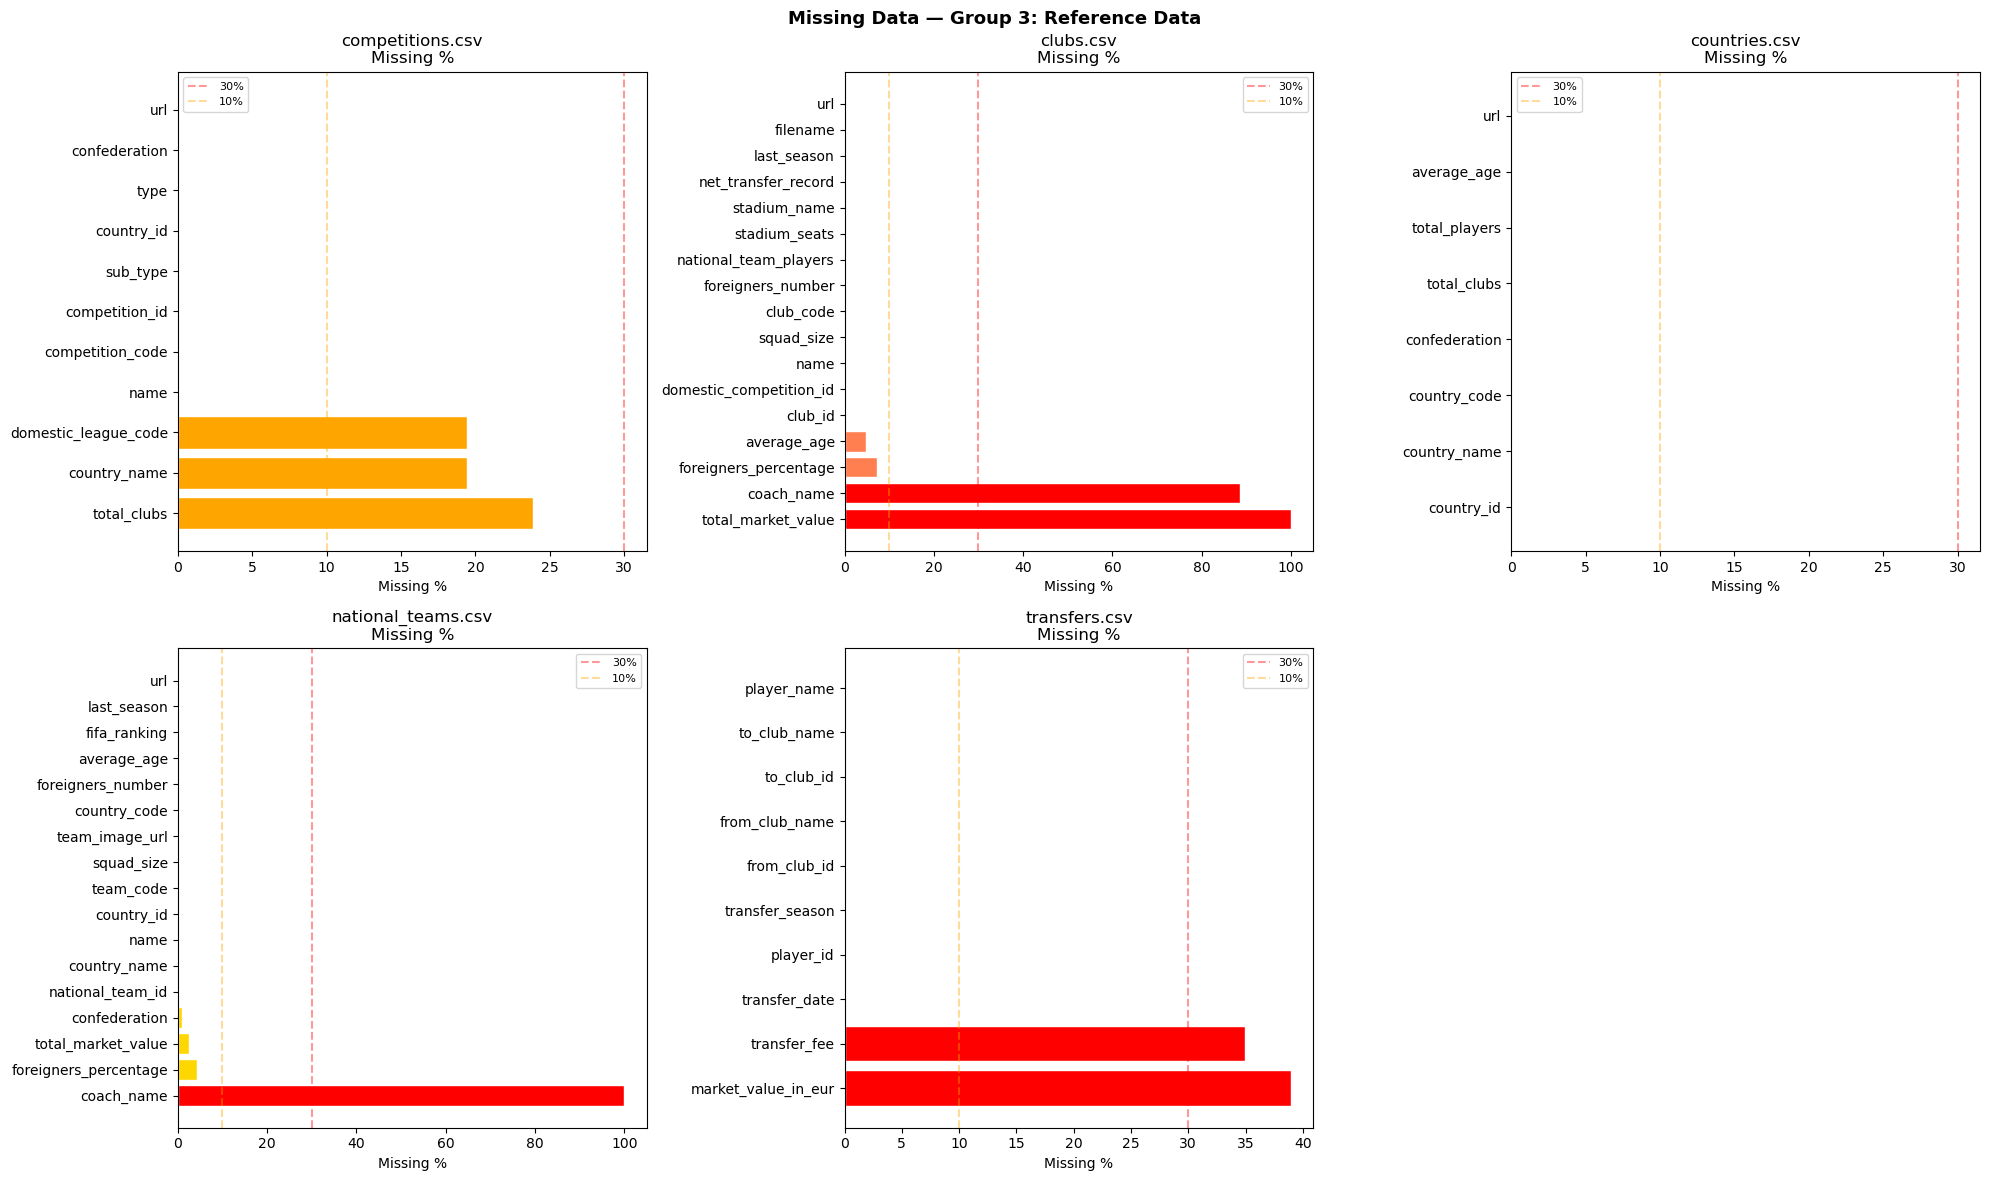

✅ Saved


In [30]:
# Missing Visualization: All 5 files

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes_flat = axes.flatten()

files_info = [
    (competitions,   'competitions.csv',   'steelblue'),
    (clubs,          'clubs.csv',          'coral'),
    (countries,      'countries.csv',      'mediumseagreen'),
    (national_teams, 'national_teams.csv', 'gold'),
    (transfers,      'transfers.csv',      'purple')
]

for ax, (df_f, name, color) in zip(axes_flat, files_info):
    pct = (df_f.isnull().sum() / len(df_f) * 100).sort_values(ascending=False)
    bar_colors = ['red' if p > 30 else 'orange' if p > 10 else color
                  for p in pct.values]
    ax.barh(pct.index, pct.values, color=bar_colors, edgecolor='white')
    ax.set_title(f'{name}\nMissing %')
    ax.set_xlabel('Missing %')
    ax.axvline(30, color='red',    linestyle='--', alpha=0.4, label='30%')
    ax.axvline(10, color='orange', linestyle='--', alpha=0.4, label='10%')
    ax.legend(fontsize=8)

# Hide last empty subplot
axes_flat[5].set_visible(False)

plt.suptitle('Missing Data — Group 3: Reference Data',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_group3_missing_data_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved")

In [31]:
# competition.csv/basic_info + univariate

print("=" * 60)
print("FILE 1: competitions.csv")
print("=" * 60)
print(f"Purpose : Lookup table — competition_id → league name")
print(f"Shape   : {competitions.shape}")
print(f"\nColumns: {competitions.columns.tolist()}")
print(f"\nAll competitions:")
print(competitions[['competition_id', 'name', 'country_name', 
                     'type', 'confederation']].to_string(index=False))

FILE 1: competitions.csv
Purpose : Lookup table — competition_id → league name
Shape   : (67, 11)

Columns: ['competition_id', 'competition_code', 'name', 'sub_type', 'type', 'country_id', 'country_name', 'domestic_league_code', 'confederation', 'total_clubs', 'url']

All competitions:
competition_id                              name   country_name                      type confederation
            A1                        bundesliga        Austria           domestic_league        europa
          AFAC                     afc-asian-cup            NaN national_team_competition         asien
          AFCN             africa-cup-of-nations            NaN national_team_competition        afrika
          ARG1                   torneo-apertura      Argentina           domestic_league       amerika
          AUS1                      a-league-men      Australia           domestic_league         asien
           BE1                jupiler-pro-league        Belgium           domestic_league

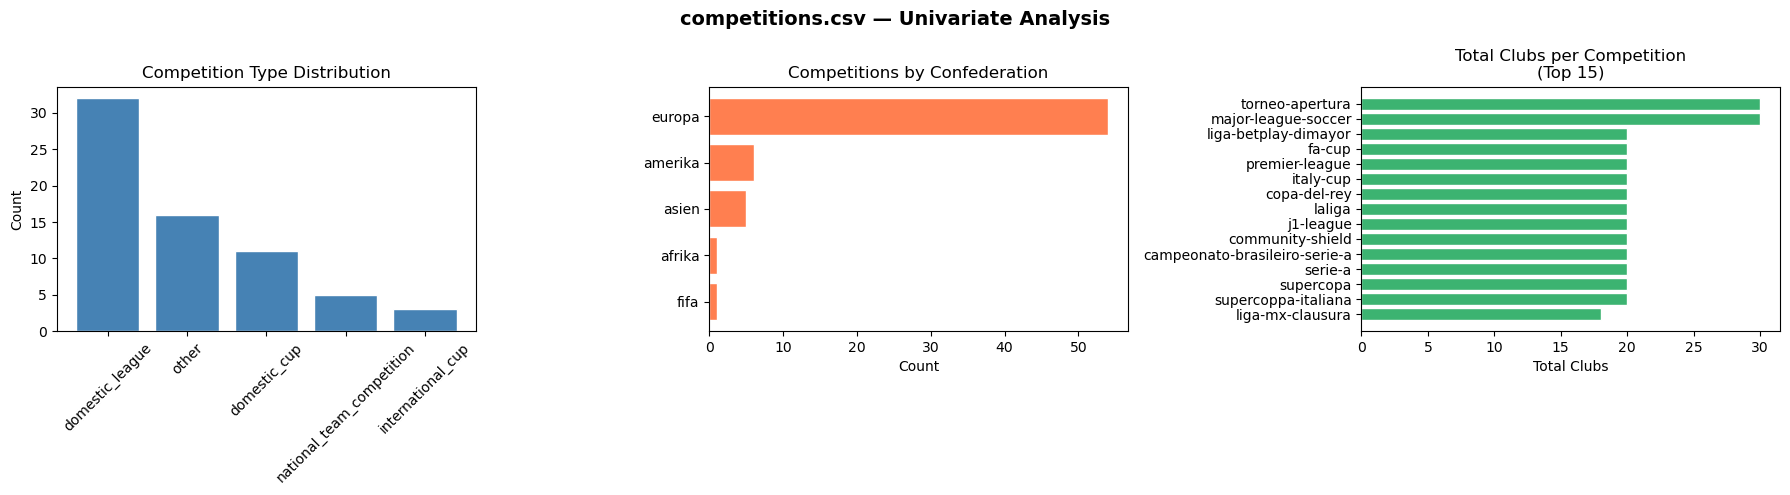

Saved


In [32]:
# competition.csv/univariate

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Type distribution
type_counts = competitions['type'].value_counts()
axes[0].bar(type_counts.index, type_counts.values,
            color='steelblue', edgecolor='white')
axes[0].set_title('Competition Type Distribution')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Confederation distribution
conf_counts = competitions['confederation'].value_counts()
axes[1].barh(conf_counts.index, conf_counts.values,
             color='coral', edgecolor='white')
axes[1].set_title('Competitions by Confederation')
axes[1].set_xlabel('Count')
axes[1].invert_yaxis()

# Total clubs per competition (top 15)
top_clubs = competitions.dropna(subset=['total_clubs'])\
                        .sort_values('total_clubs', ascending=False).head(15)
axes[2].barh(top_clubs['name'], top_clubs['total_clubs'],
             color='mediumseagreen', edgecolor='white')
axes[2].set_title('Total Clubs per Competition\n(Top 15)')
axes[2].set_xlabel('Total Clubs')
axes[2].invert_yaxis()

plt.suptitle('competitions.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '02_competitions_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

FILE 2: clubs.csv
Purpose : Club profile (stadium, squad size, market value)
Shape   : (796, 17)

Columns: ['club_id', 'club_code', 'name', 'domestic_competition_id', 'total_market_value', 'squad_size', 'average_age', 'foreigners_number', 'foreigners_percentage', 'national_team_players', 'stadium_name', 'stadium_seats', 'net_transfer_record', 'coach_name', 'last_season', 'filename', 'url']


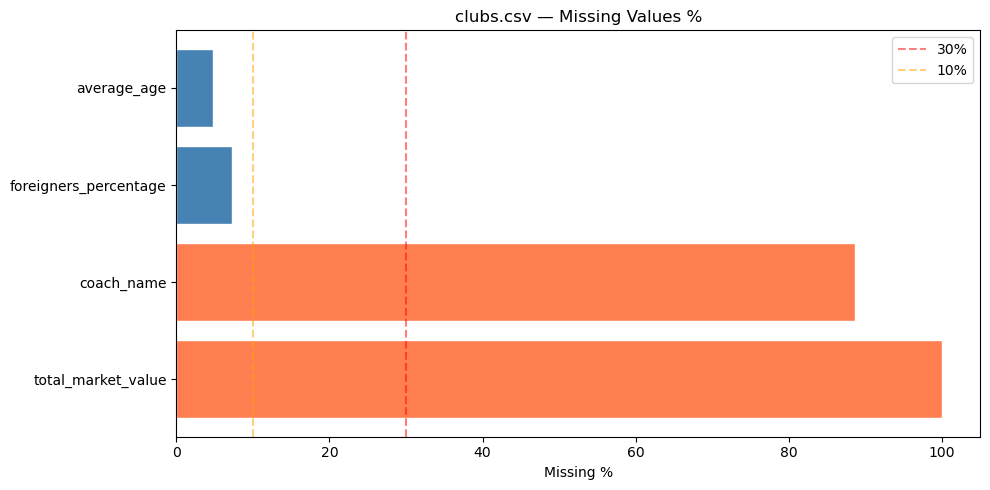


Missing Values Detail:
                       count  percent
total_market_value       796   100.00
coach_name               706    88.69
foreigners_percentage     58     7.29
average_age               38     4.77


In [33]:
# club.csv/basic_info + missing

print("=" * 60)
print("FILE 2: clubs.csv")
print("=" * 60)
print(f"Purpose : Club profile (stadium, squad size, market value)")
print(f"Shape   : {clubs.shape}")
print(f"\nColumns: {clubs.columns.tolist()}")

# Missing values
missing_clubs = pd.DataFrame({
    'count'  : clubs.isnull().sum(),
    'percent': (clubs.isnull().sum() / len(clubs) * 100).round(2)
}).sort_values('percent', ascending=False)

missing_only = missing_clubs[missing_clubs['count'] > 0]

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['coral' if p > 30 else 'orange' if p > 10 else 'steelblue'
          for p in missing_only['percent']]
ax.barh(missing_only.index, missing_only['percent'],
        color=colors, edgecolor='white')
ax.set_title('clubs.csv — Missing Values %')
ax.set_xlabel('Missing %')
ax.axvline(30, color='red', linestyle='--', alpha=0.5, label='30%')
ax.axvline(10, color='orange', linestyle='--', alpha=0.5, label='10%')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_clubs_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nMissing Values Detail:")
print(missing_only.to_string())

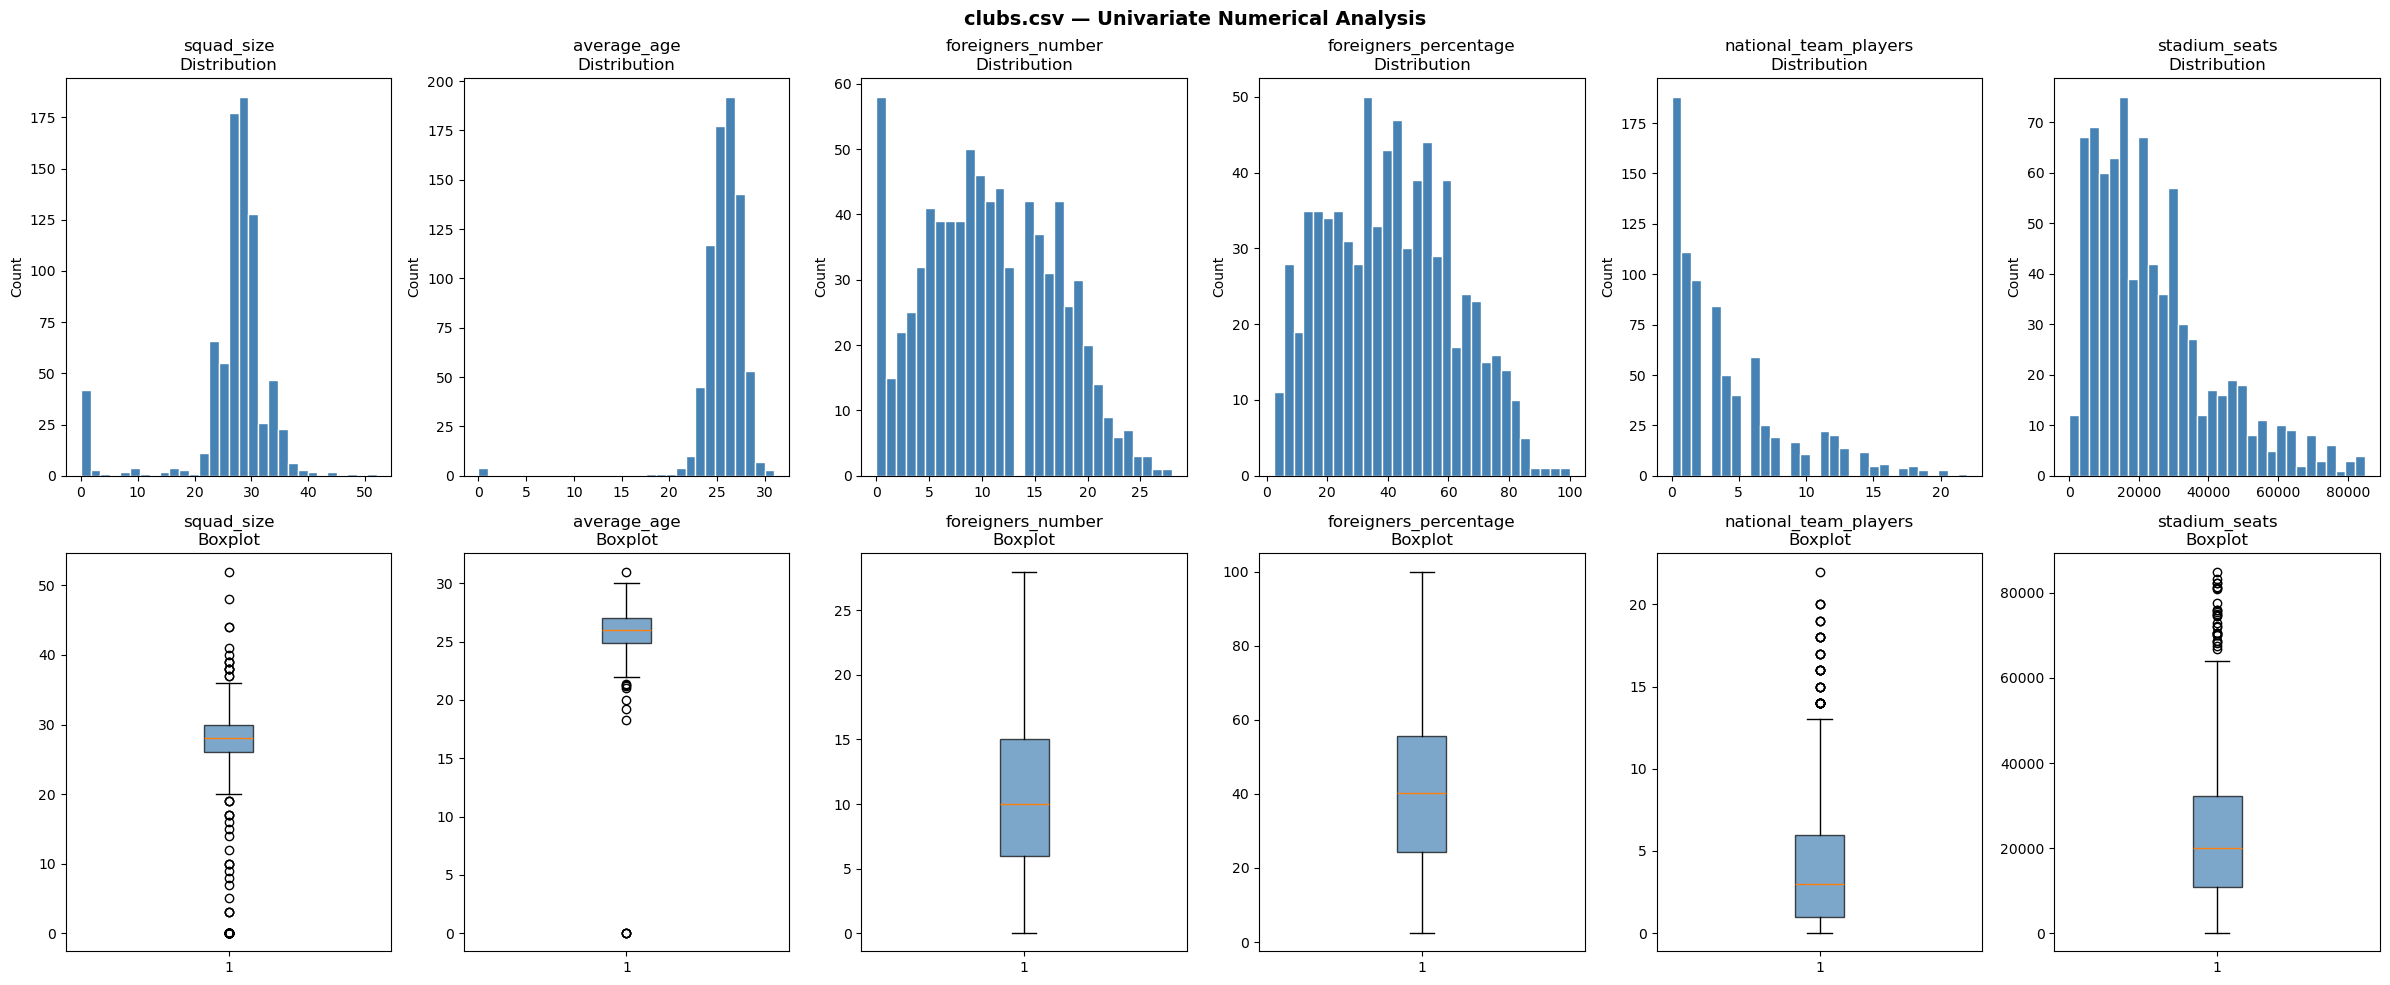

Saved


In [34]:
# club.csv/univariate

numerical_clubs = ['squad_size', 'average_age', 
                   'foreigners_number', 'foreigners_percentage',
                   'national_team_players', 'stadium_seats']

fig, axes = plt.subplots(2, len(numerical_clubs), figsize=(24, 10))

for i, col in enumerate(numerical_clubs):
    data = clubs[col].dropna()

    # Histogram
    axes[0, i].hist(data, bins=30, color='steelblue', edgecolor='white')
    axes[0, i].set_title(f'{col}\nDistribution')
    axes[0, i].set_ylabel('Count')

    # Boxplot
    axes[1, i].boxplot(data, patch_artist=True,
                       boxprops=dict(facecolor='steelblue', alpha=0.7))
    axes[1, i].set_title(f'{col}\nBoxplot')

plt.suptitle('clubs.csv — Univariate Numerical Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_clubs_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

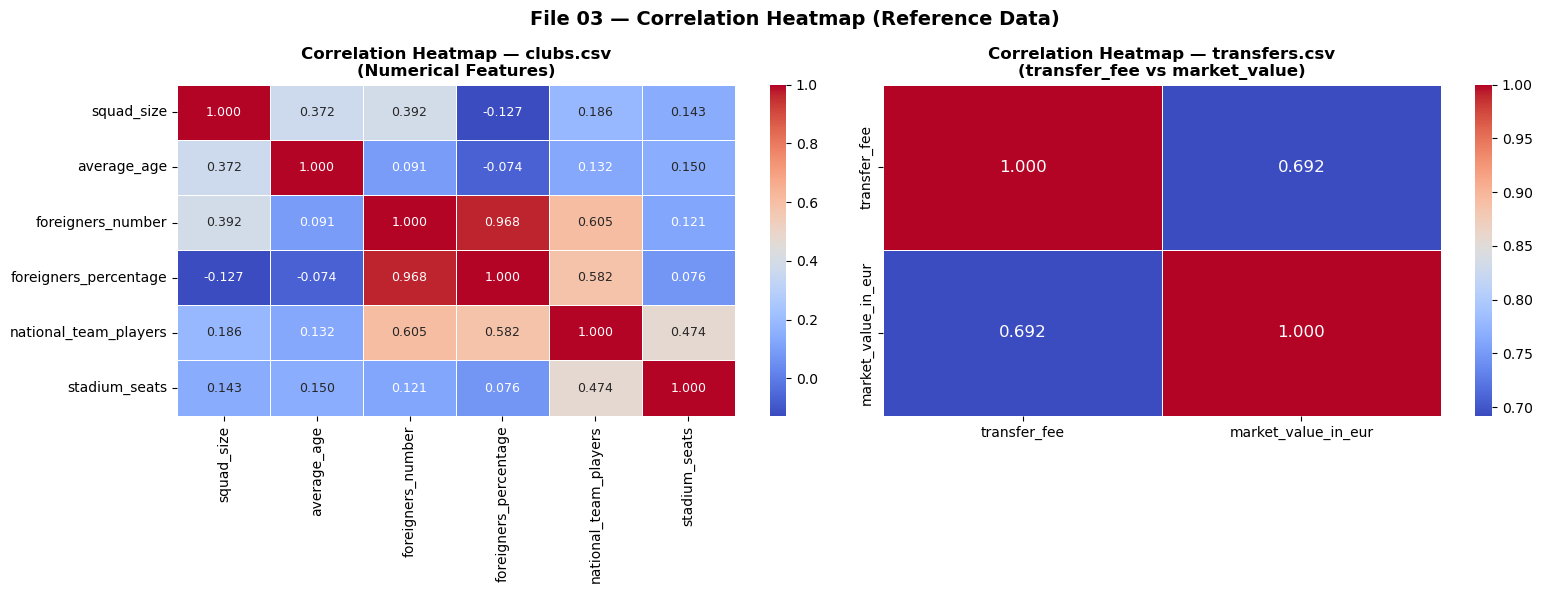

✅ Saved


In [35]:
# Correlation Heatmap — clubs.csv + transfers.csv
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap — clubs.csv
numerical_clubs = ['squad_size', 'average_age', 'foreigners_number',
                   'foreigners_percentage', 'national_team_players',
                   'stadium_seats']
corr_clubs = clubs[numerical_clubs].corr()
sns.heatmap(corr_clubs, annot=True, fmt='.3f',
            cmap='coolwarm', linewidths=0.5,
            ax=axes[0], annot_kws={'size': 9})
axes[0].set_title('Correlation Heatmap — clubs.csv\n(Numerical Features)',
                  fontsize=12, fontweight='bold')

# Heatmap — transfers.csv
numerical_transfers = ['transfer_fee', 'market_value_in_eur']
corr_transfers = transfers[numerical_transfers].dropna().corr()
sns.heatmap(corr_transfers, annot=True, fmt='.3f',
            cmap='coolwarm', linewidths=0.5,
            ax=axes[1], annot_kws={'size': 12})
axes[1].set_title('Correlation Heatmap — transfers.csv\n(transfer_fee vs market_value)',
                  fontsize=12, fontweight='bold')

plt.suptitle('File 03 — Correlation Heatmap (Reference Data)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_reference_data_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved")

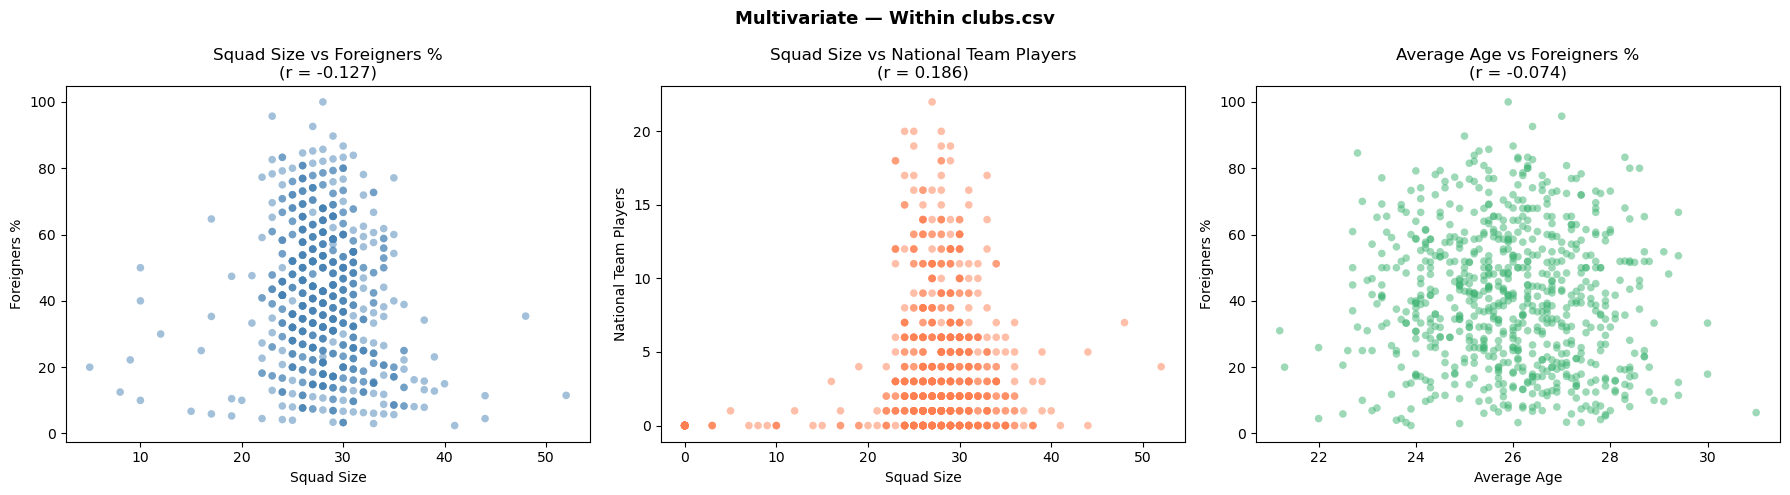

Saved


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Squad size vs Foreigners %
axes[0].scatter(clubs['squad_size'],
                clubs['foreigners_percentage'],
                alpha=0.5, color='steelblue', edgecolors='none', s=30)
corr1 = clubs['squad_size'].corr(clubs['foreigners_percentage'])
axes[0].set_title(f'Squad Size vs Foreigners %\n(r = {corr1:.3f})')
axes[0].set_xlabel('Squad Size')
axes[0].set_ylabel('Foreigners %')

# Squad size vs National team players
axes[1].scatter(clubs['squad_size'],
                clubs['national_team_players'],
                alpha=0.5, color='coral', edgecolors='none', s=30)
corr2 = clubs['squad_size'].corr(clubs['national_team_players'])
axes[1].set_title(f'Squad Size vs National Team Players\n(r = {corr2:.3f})')
axes[1].set_xlabel('Squad Size')
axes[1].set_ylabel('National Team Players')

# Average age vs Foreigners %
axes[2].scatter(clubs['average_age'],
                clubs['foreigners_percentage'],
                alpha=0.5, color='mediumseagreen', edgecolors='none', s=30)
corr3 = clubs['average_age'].corr(clubs['foreigners_percentage'])
axes[2].set_title(f'Average Age vs Foreigners %\n(r = {corr3:.3f})')
axes[2].set_xlabel('Average Age')
axes[2].set_ylabel('Foreigners %')

plt.suptitle('Multivariate — Within clubs.csv',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '06_clubs_multivariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

FILE 3: countries.csv
Purpose : Country info (confederation, total clubs/players)
Shape   : (118, 8)
Missing : 0 ← perfectly clean!

Columns: ['country_id', 'country_name', 'country_code', 'confederation', 'total_clubs', 'total_players', 'average_age', 'url']


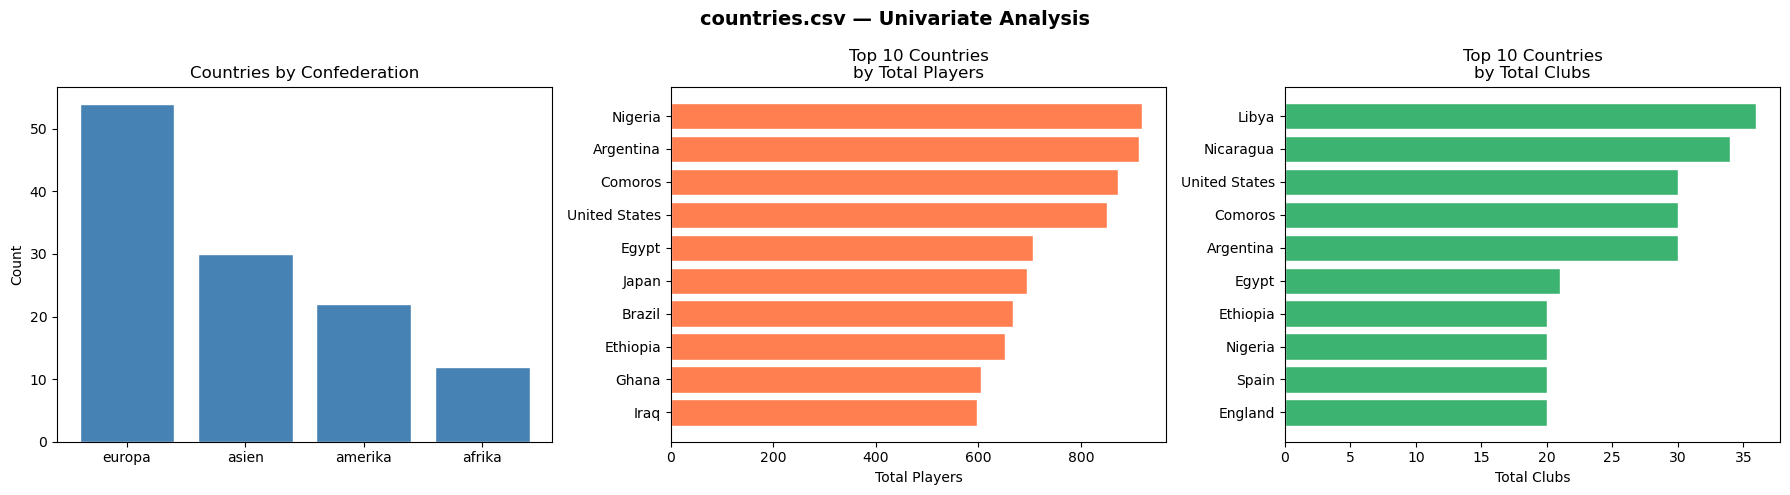

Saved


In [37]:
# countries.csv/basic_info + univariate

print("=" * 60)
print("FILE 3: countries.csv")
print("=" * 60)
print(f"Purpose : Country info (confederation, total clubs/players)")
print(f"Shape   : {countries.shape}")
print(f"Missing : {countries.isnull().sum().sum()} ← perfectly clean!")
print(f"\nColumns: {countries.columns.tolist()}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confederation distribution
conf = countries['confederation'].value_counts()
axes[0].bar(conf.index, conf.values,
            color='steelblue', edgecolor='white')
axes[0].set_title('Countries by Confederation')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Top 10 countries by total players
top_players = countries.nlargest(10, 'total_players')
axes[1].barh(top_players['country_name'], top_players['total_players'],
             color='coral', edgecolor='white')
axes[1].set_title('Top 10 Countries\nby Total Players')
axes[1].set_xlabel('Total Players')
axes[1].invert_yaxis()

# Top 10 countries by total clubs
top_clubs = countries.nlargest(10, 'total_clubs')
axes[2].barh(top_clubs['country_name'], top_clubs['total_clubs'],
             color='mediumseagreen', edgecolor='white')
axes[2].set_title('Top 10 Countries\nby Total Clubs')
axes[2].set_xlabel('Total Clubs')
axes[2].invert_yaxis()

plt.suptitle('countries.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_countries_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

FILE 4: national_teams.csv
Purpose : National team info (FIFA ranking, squad)
Shape   : (118, 17)

Missing Values:
                       count  percent
confederation              1     0.85
foreigners_percentage      5     4.24
total_market_value         3     2.54
coach_name               118   100.00


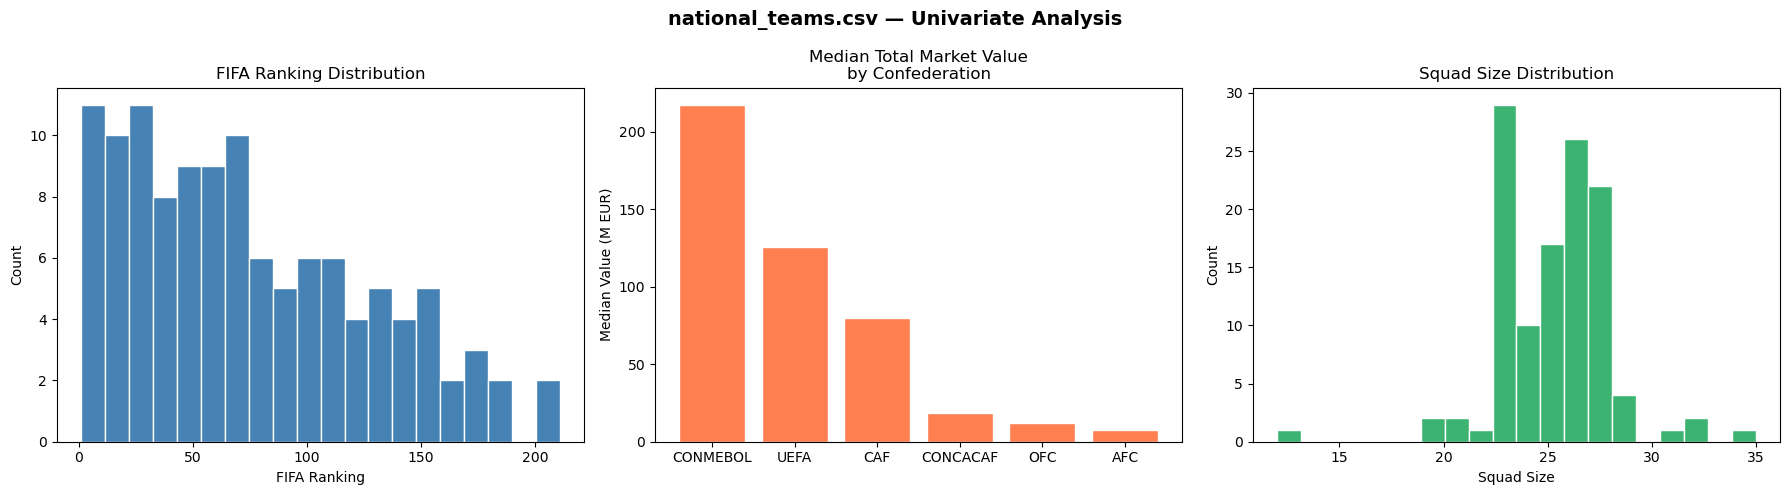

Saved


In [38]:
# national_team.csv/basic_info + univariate

print("=" * 60)
print("FILE 4: national_teams.csv")
print("=" * 60)
print(f"Purpose : National team info (FIFA ranking, squad)")
print(f"Shape   : {national_teams.shape}")

# Missing
missing_nt = pd.DataFrame({
    'count'  : national_teams.isnull().sum(),
    'percent': (national_teams.isnull().sum() / len(national_teams) * 100).round(2)
})
print("\nMissing Values:")
print(missing_nt[missing_nt['count'] > 0].to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# FIFA ranking distribution
axes[0].hist(national_teams['fifa_ranking'].dropna(),
             bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('FIFA Ranking Distribution')
axes[0].set_xlabel('FIFA Ranking')
axes[0].set_ylabel('Count')

# Total market value by confederation
nt_conf = national_teams.groupby('confederation')['total_market_value']\
                         .median().dropna().sort_values(ascending=False)
axes[1].bar(nt_conf.index, nt_conf.values / 1_000_000,
            color='coral', edgecolor='white')
axes[1].set_title('Median Total Market Value\nby Confederation')
axes[1].set_ylabel('Median Value (M EUR)')
axes[1].tick_params(axis='x', rotation=0)

# Squad size distribution
axes[2].hist(national_teams['squad_size'].dropna(),
             bins=20, color='mediumseagreen', edgecolor='white')
axes[2].set_title('Squad Size Distribution')
axes[2].set_xlabel('Squad Size')
axes[2].set_ylabel('Count')

plt.suptitle('national_teams.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_national_teams_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

In [39]:
# transfer.csv/basic_info + missing

print("=" * 60)
print("FILE 5: transfers.csv")
print("=" * 60)
print(f"Purpose : Transfer history (fee, from/to club)")
print(f"Shape   : {transfers.shape}")
print(f"\nColumns: {transfers.columns.tolist()}")

# Missing
missing_transfers = pd.DataFrame({
    'count'  : transfers.isnull().sum(),
    'percent': (transfers.isnull().sum() / len(transfers) * 100).round(2)
}).sort_values('percent', ascending=False)

print("\nMissing Values:")
print(missing_transfers[missing_transfers['count'] > 0].to_string())

transfers['transfer_date'] = pd.to_datetime(transfers['transfer_date'])
print(f"\nDate range: {transfers['transfer_date'].min()} → {transfers['transfer_date'].max()}")
print(f"\nTransfer fee stats (non-null):")
print(transfers['transfer_fee'].describe().round(2))

FILE 5: transfers.csv
Purpose : Transfer history (fee, from/to club)
Shape   : (173653, 10)

Columns: ['player_id', 'transfer_date', 'transfer_season', 'from_club_id', 'to_club_id', 'from_club_name', 'to_club_name', 'transfer_fee', 'market_value_in_eur', 'player_name']

Missing Values:
                     count  percent
market_value_in_eur  67658    38.96
transfer_fee         60719    34.97

Date range: 1993-07-01 00:00:00 → 2030-06-30 00:00:00

Transfer fee stats (non-null):
count    1.129340e+05
mean     7.404548e+05
std      4.247468e+06
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.220000e+08
Name: transfer_fee, dtype: float64


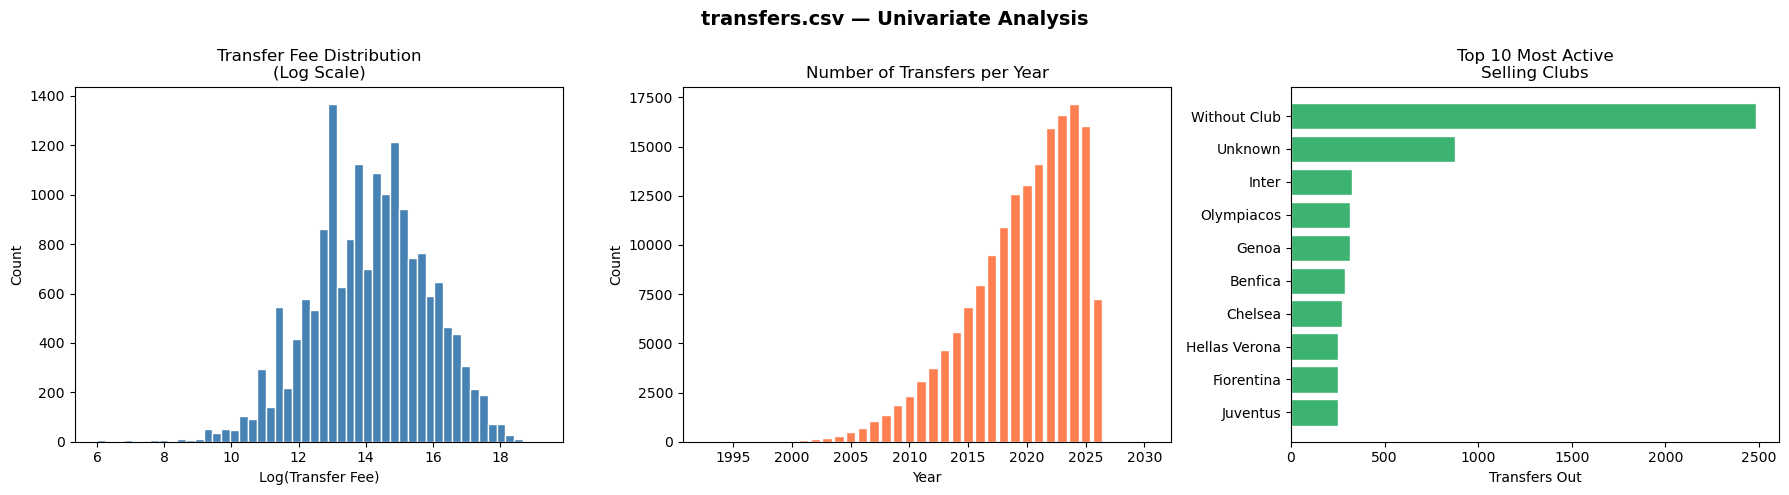

Saved


"\nData Note:\nThe transfer dataset contains special club values such as\n'Without Club' and 'Unknown'.\n\n- Without Club: player was unattached/free agent before transfer.\n- Unknown: source club information is unavailable.\n\nThese records are intentionally retained throughout the analysis\nto avoid losing potentially meaningful transfer information.\n"

In [40]:
# transfer.csv/Univariate

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Transfer fee distribution (log)
fee_data = transfers['transfer_fee'].dropna()
fee_data = fee_data[fee_data > 0]
axes[0].hist(np.log1p(fee_data), bins=50,
             color='steelblue', edgecolor='white')
axes[0].set_title('Transfer Fee Distribution\n(Log Scale)')
axes[0].set_xlabel('Log(Transfer Fee)')
axes[0].set_ylabel('Count')

# Transfers per year
yearly_transfers = transfers.groupby(
    transfers['transfer_date'].dt.year
).size()
axes[1].bar(yearly_transfers.index, yearly_transfers.values,
            color='coral', edgecolor='white')
axes[1].set_title('Number of Transfers per Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=0)

# Top 10 most active selling clubs
top_sellers = transfers['from_club_name'].value_counts().head(10)
axes[2].barh(top_sellers.index, top_sellers.values,
             color='mediumseagreen', edgecolor='white')
axes[2].set_title('Top 10 Most Active\nSelling Clubs')
axes[2].set_xlabel('Transfers Out')
axes[2].invert_yaxis()

plt.suptitle('transfers.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '09_transfers_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

"""
Data Note:
The transfer dataset contains special club values such as
'Without Club' and 'Unknown'.

- Without Club: player was unattached/free agent before transfer.
- Unknown: source club information is unavailable.

These records are intentionally retained throughout the analysis
to avoid losing potentially meaningful transfer information.
"""

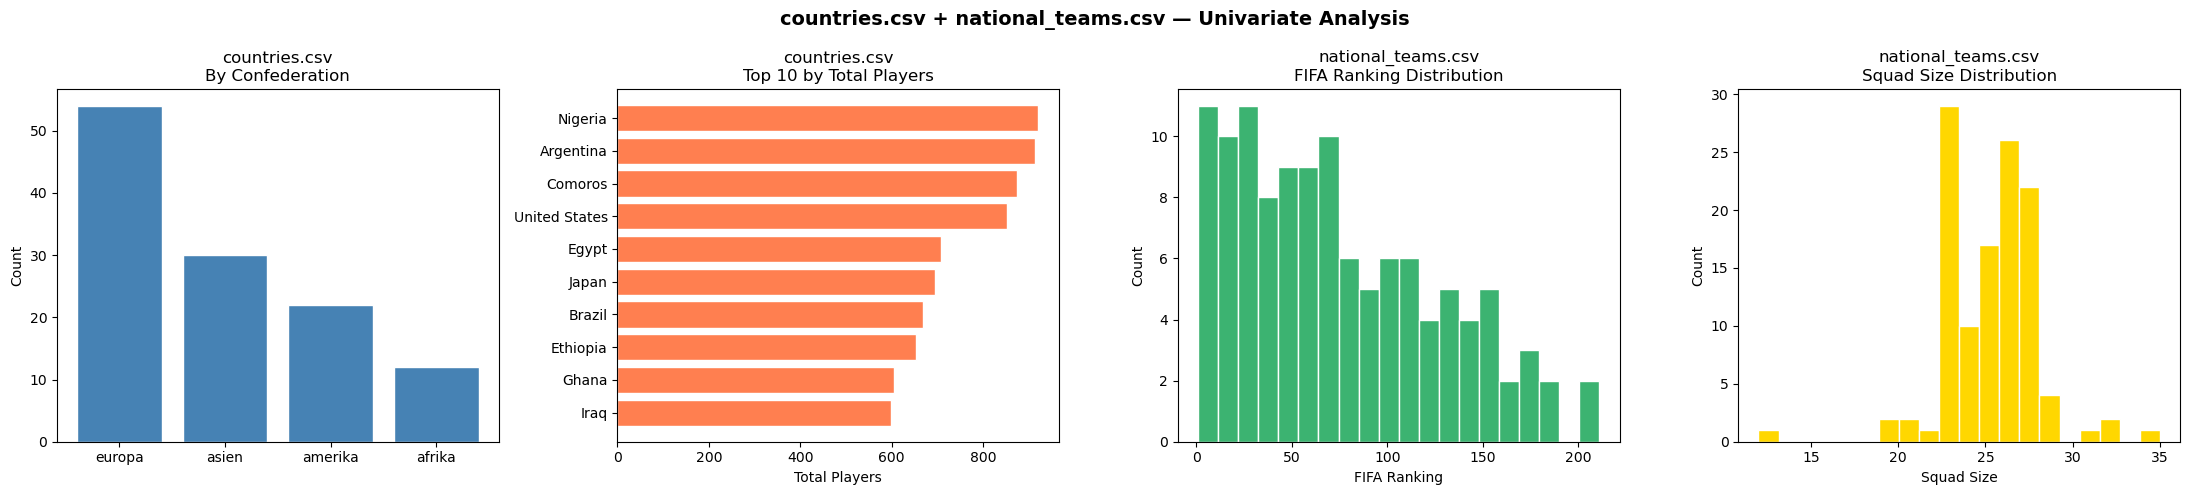

✅ Saved


In [41]:
# Univariate: countries.csv + national_teams.csv

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Countries by confederation
conf = countries['confederation'].value_counts()
axes[0].bar(conf.index, conf.values,
            color='steelblue', edgecolor='white')
axes[0].set_title('countries.csv\nBy Confederation')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Top 10 countries by players
top_players = countries.nlargest(10, 'total_players')
axes[1].barh(top_players['country_name'],
             top_players['total_players'],
             color='coral', edgecolor='white')
axes[1].set_title('countries.csv\nTop 10 by Total Players')
axes[1].set_xlabel('Total Players')
axes[1].invert_yaxis()

# FIFA ranking distribution
axes[2].hist(national_teams['fifa_ranking'].dropna(),
             bins=20, color='mediumseagreen', edgecolor='white')
axes[2].set_title('national_teams.csv\nFIFA Ranking Distribution')
axes[2].set_xlabel('FIFA Ranking')
axes[2].set_ylabel('Count')

# Squad size distribution
axes[3].hist(national_teams['squad_size'].dropna(),
             bins=20, color='gold', edgecolor='white')
axes[3].set_title('national_teams.csv\nSquad Size Distribution')
axes[3].set_xlabel('Squad Size')
axes[3].set_ylabel('Count')

plt.suptitle('countries.csv + national_teams.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '10_countries_and_national_teams_univariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved")

players × clubs merged: (39175, 32)


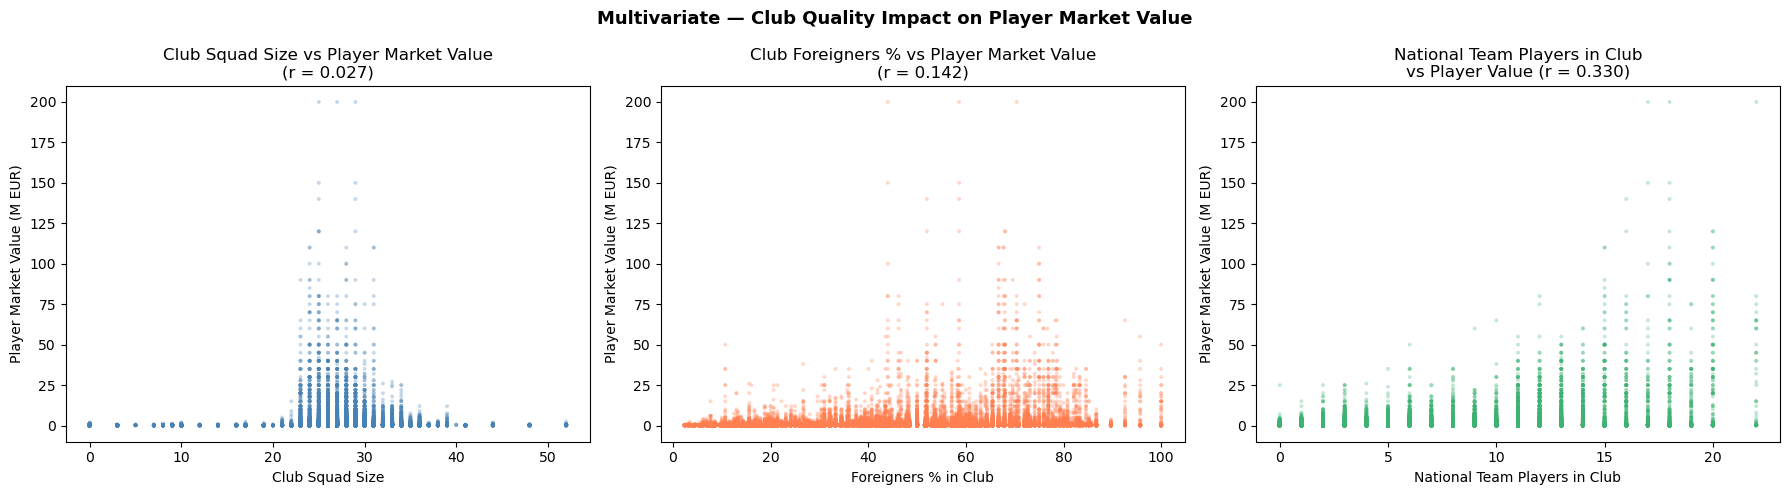

Saved


In [42]:
# Cell 14 — clubs × players → club quality affects value

players = pd.read_csv('../../data/raw/players.csv')

# Merge players + clubs
players_clubs = players.merge(
    clubs[['club_id', 'squad_size', 'average_age',
           'foreigners_percentage', 'national_team_players',
           'domestic_competition_id']],
    left_on='current_club_id', right_on='club_id', how='inner'
).dropna(subset=['market_value_in_eur'])

print(f"players × clubs merged: {players_clubs.shape}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Squad size vs player market value
corr1 = players_clubs['squad_size'].corr(
    players_clubs['market_value_in_eur']
)
axes[0].scatter(players_clubs['squad_size'],
                players_clubs['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='steelblue', edgecolors='none', s=8)
axes[0].set_title(f'Club Squad Size vs Player Market Value\n(r = {corr1:.3f})')
axes[0].set_xlabel('Club Squad Size')
axes[0].set_ylabel('Player Market Value (M EUR)')

# Foreigners % vs player market value
corr2 = players_clubs['foreigners_percentage'].corr(
    players_clubs['market_value_in_eur']
)
axes[1].scatter(players_clubs['foreigners_percentage'],
                players_clubs['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='coral', edgecolors='none', s=8)
axes[1].set_title(f'Club Foreigners % vs Player Market Value\n(r = {corr2:.3f})')
axes[1].set_xlabel('Foreigners % in Club')
axes[1].set_ylabel('Player Market Value (M EUR)')

# National team players in club vs player value
corr3 = players_clubs['national_team_players'].corr(
    players_clubs['market_value_in_eur']
)
axes[2].scatter(players_clubs['national_team_players'],
                players_clubs['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='mediumseagreen', edgecolors='none', s=8)
axes[2].set_title(f'National Team Players in Club\nvs Player Value (r = {corr3:.3f})')
axes[2].set_xlabel('National Team Players in Club')
axes[2].set_ylabel('Player Market Value (M EUR)')

plt.suptitle('Multivariate — Club Quality Impact on Player Market Value',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '11_club_quality_vs_player_market_value.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved") 

# Chat luong cua CLB anh huong the nao den Market Value cua cau thu?

# => Chart 1: CLB co squad lon =>  Cau thu co dat hon? 
# Neu r > 0.3:
# -> CLB lon (MC, MU, Real Madrid ¬ 35 cau thu) co cau thu dat hon CLB nho 
# -> Justify: current_club_id la useful feature
# Neu r = 0:
# -> Squad size khong anh huong nhieu
# Khong nen dung lam feature

# => Chart 2: CLB co nhieu ngoai binh -> Cau thu co dat hon khong?
# Neu r > 0.3:
# -> CLB top (Premier League) co nhieu ngoai binh va cau thu dat hon
# -> Foreigners % la proxy cho "league quality"
# Neu r = 0:
# Khong lien quan

# => Chart 3: CLB co nhieu cau thu DTQG -> individual player dat hon khong?
# CRUCIAL:
# -> CLB top (Barcelona, Bayern) co nhieu cau thu DTQG nhat
# -> Neu r cao -> "playing for top club" la strong signal cua market value
# -> Consistent voi finding : international_caps = #1 feature

# Club Quality as Market Value Predictor:

# This analysis examines whether the quality of 
# a player's current club influences their 
#market value.

#Key findings:
# → national_team_players in club: r = X
#  (CLB có nhiều ĐTQG → player đắt hơn)
# → foreigners_percentage: r = X  
#  (CLB quốc tế hóa → player đắt hơn)
# → squad_size: r = X
#  (ít ảnh hưởng nhất)

# Conclusion:
# Playing for a high-profile club (measured by
# national team players and foreign player ratio)
# is associated with higher individual market value.

# → This suggests adding club-level features
#  could improve ML model performance.
 


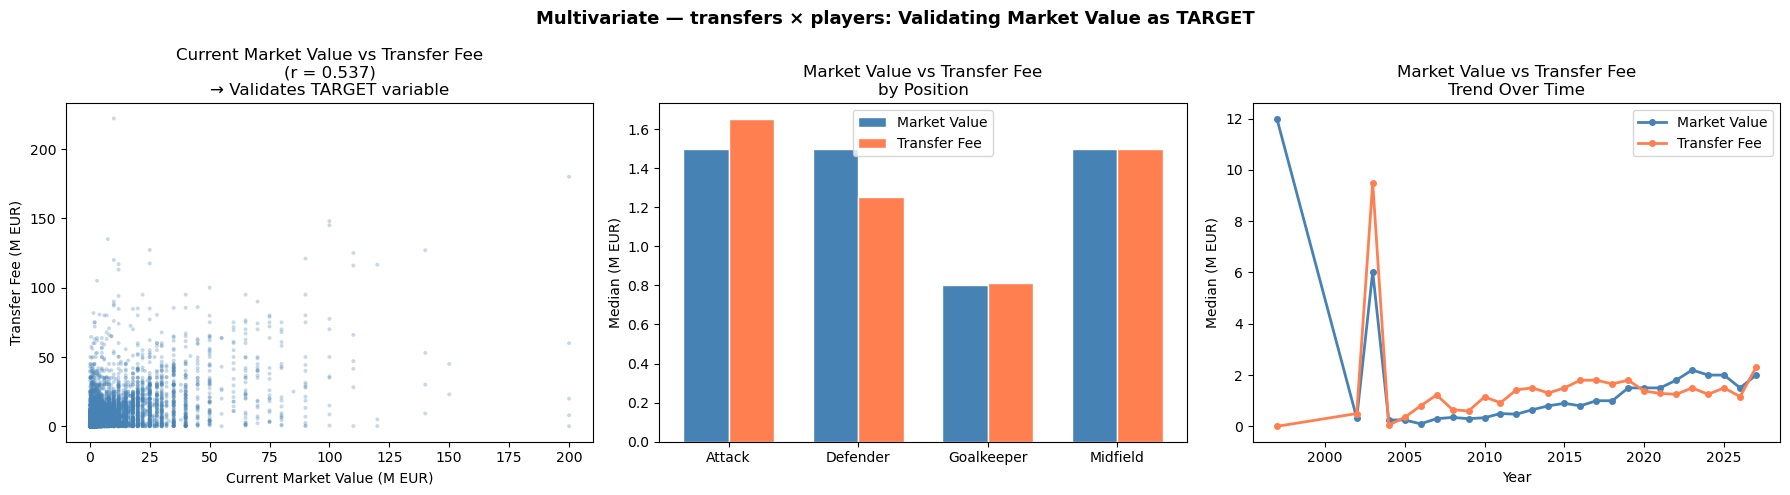

Saved


In [43]:
transfers['transfer_date'] = pd.to_datetime(transfers['transfer_date'])

players_clean = players[['player_id', 'market_value_in_eur', 'position']].copy()
players_clean = players_clean.rename(columns={
    'market_value_in_eur': 'current_market_value'
})

transfers_merged = transfers.merge(
    players_clean, on='player_id', how='inner'
).dropna(subset=['transfer_fee', 'current_market_value'])
transfers_merged = transfers_merged[transfers_merged['transfer_fee'] > 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Transfer fee vs Current market value
corr = transfers_merged['current_market_value'].corr(
    transfers_merged['transfer_fee']
)
axes[0].scatter(transfers_merged['current_market_value'] / 1_000_000,
                transfers_merged['transfer_fee'] / 1_000_000,
                alpha=0.3, color='steelblue', edgecolors='none', s=8)
axes[0].set_title(f'Current Market Value vs Transfer Fee\n(r = {corr:.3f})\n→ Validates TARGET variable')
axes[0].set_xlabel('Current Market Value (M EUR)')
axes[0].set_ylabel('Transfer Fee (M EUR)')

# Median fee vs median value by position
pos_stats = transfers_merged.groupby('position').agg(
    median_fee   = ('transfer_fee',        'median'),
    median_value = ('current_market_value', 'median')
).reset_index()

x = range(len(pos_stats))
width = 0.35
axes[1].bar([i - width/2 for i in x],
            pos_stats['median_value'] / 1_000_000,
            width, label='Market Value', color='steelblue', edgecolor='white')
axes[1].bar([i + width/2 for i in x],
            pos_stats['median_fee'] / 1_000_000,
            width, label='Transfer Fee', color='coral', edgecolor='white')
axes[1].set_title('Market Value vs Transfer Fee\nby Position')
axes[1].set_ylabel('Median (M EUR)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(pos_stats['position'])
axes[1].legend()

# Transfer fee trend vs market inflation
yearly = transfers_merged.groupby(
    transfers_merged['transfer_date'].dt.year
).agg(
    median_fee   = ('transfer_fee',        'median'),
    median_value = ('current_market_value', 'median')
)
axes[2].plot(yearly.index, yearly['median_value'] / 1_000_000,
             color='steelblue', linewidth=2, marker='o',
             markersize=4, label='Market Value')
axes[2].plot(yearly.index, yearly['median_fee'] / 1_000_000,
             color='coral', linewidth=2, marker='o',
             markersize=4, label='Transfer Fee')
axes[2].set_title('Market Value vs Transfer Fee\nTrend Over Time')
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Median (M EUR)')
axes[2].legend()
axes[2].tick_params(axis='x', rotation=0)

plt.suptitle('Multivariate — transfers × players: Validating Market Value as TARGET',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '12_transfers_validate_market_value_target.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved") # transfer.csv da co san cot market_value_in_eur -> merge voi player.csv 
# cung co cot nay => pandas tao. ra market_value_in_eur_x va  market_value_in_eur_y -> dropna ko tim thay ten goc nen phai rename trc khi merge

national_teams × countries merged: (115, 19)


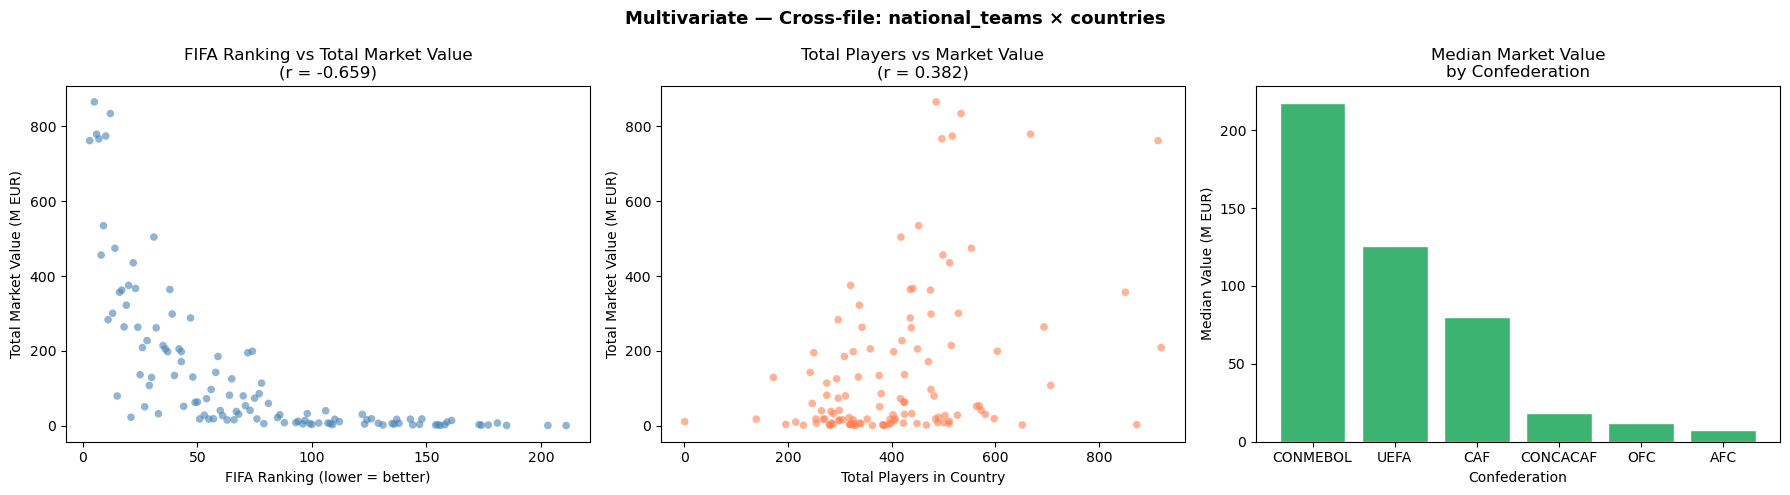

Saved


In [44]:
# Multivariate: national_teams × countries

# Merge national_teams + countries
nt_merged = national_teams.merge(
    countries[['country_name', 'total_players', 'total_clubs']],
    on='country_name', how='inner'
).dropna(subset=['fifa_ranking', 'total_market_value'])

print(f"national_teams × countries merged: {nt_merged.shape}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# FIFA ranking vs Total market value
axes[0].scatter(nt_merged['fifa_ranking'],
                nt_merged['total_market_value'] / 1_000_000,
                alpha=0.6, color='steelblue', edgecolors='none', s=30)
corr1 = nt_merged['fifa_ranking'].corr(nt_merged['total_market_value'])
axes[0].set_title(f'FIFA Ranking vs Total Market Value\n(r = {corr1:.3f})')
axes[0].set_xlabel('FIFA Ranking (lower = better)')
axes[0].set_ylabel('Total Market Value (M EUR)')

# Total players vs Market value
axes[1].scatter(nt_merged['total_players'],
                nt_merged['total_market_value'] / 1_000_000,
                alpha=0.6, color='coral', edgecolors='none', s=30)
corr2 = nt_merged['total_players'].corr(nt_merged['total_market_value'])
axes[1].set_title(f'Total Players vs Market Value\n(r = {corr2:.3f})')
axes[1].set_xlabel('Total Players in Country')
axes[1].set_ylabel('Total Market Value (M EUR)')

# Market value by confederation
conf_value = nt_merged.groupby('confederation')['total_market_value']\
                       .median().sort_values(ascending=False)
axes[2].bar(conf_value.index, conf_value.values / 1_000_000,
            color='mediumseagreen', edgecolor='white')
axes[2].set_title('Median Market Value\nby Confederation')
axes[2].set_xlabel('Confederation')
axes[2].set_ylabel('Median Value (M EUR)')
axes[2].tick_params(axis='x', rotation=0)

plt.suptitle('Multivariate — Cross-file: national_teams × countries',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '13_national_teams_vs_countries_multivariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved") # exponential distribution

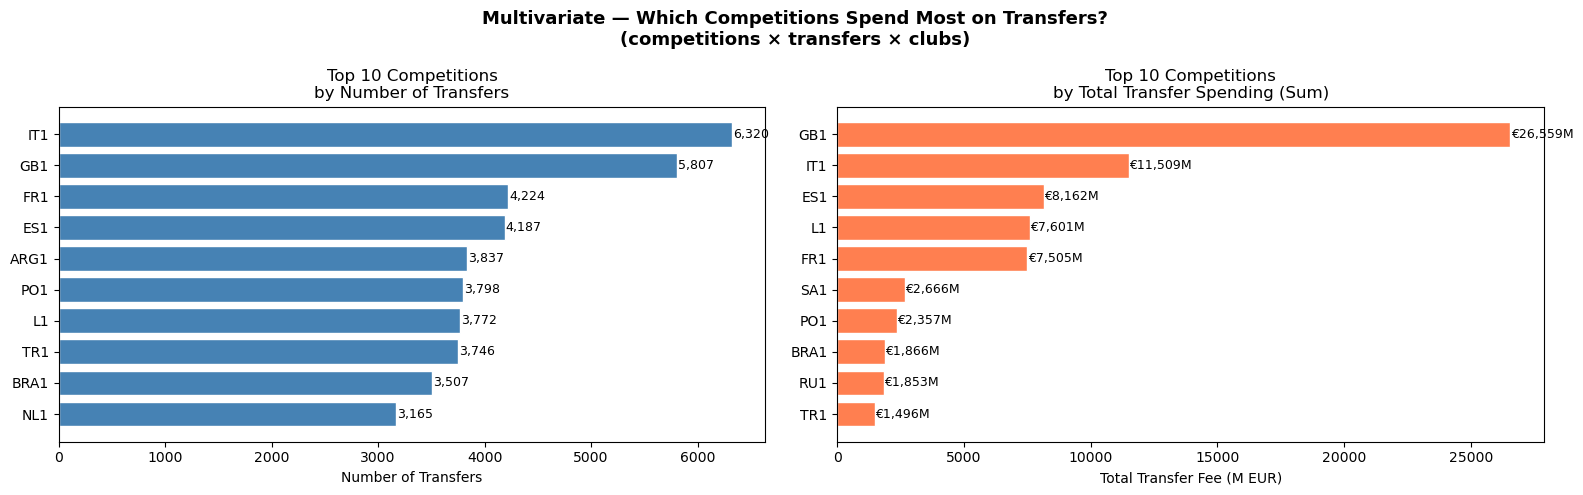

Saved


In [45]:
# Multivariate: competitions × transfers
transfers['transfer_date'] = pd.to_datetime(transfers['transfer_date'])

# Merge transfers + clubs
top_comp_transfers = transfers.merge(
    clubs[['club_id', 'domestic_competition_id']],
    left_on='to_club_id', right_on='club_id', how='inner'
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 by number of transfers
top_comp = top_comp_transfers['domestic_competition_id']\
           .value_counts().head(10)
axes[0].barh(top_comp.index, top_comp.values,
             color='steelblue', edgecolor='white')
axes[0].set_title('Top 10 Competitions\nby Number of Transfers')
axes[0].set_xlabel('Number of Transfers')
axes[0].invert_yaxis()
for i, v in enumerate(top_comp.values):
    axes[0].text(v + 10, i, f'{v:,}', va='center', fontsize=9)

# Top 10 by SUM transfer fee
comp_fee_sum = top_comp_transfers[top_comp_transfers['transfer_fee'] > 0]\
               .groupby('domestic_competition_id')['transfer_fee']\
               .sum().sort_values(ascending=False).head(10)  # ← sum thay median

axes[1].barh(comp_fee_sum.index, comp_fee_sum.values / 1_000_000,
             color='coral', edgecolor='white')
axes[1].set_title('Top 10 Competitions\nby Total Transfer Spending (Sum)')
axes[1].set_xlabel('Total Transfer Fee (M EUR)')
axes[1].invert_yaxis()
for i, v in enumerate(comp_fee_sum.values / 1_000_000):
    axes[1].text(v + 10, i, f'€{v:,.0f}M', va='center', fontsize=9)

plt.suptitle('Multivariate — Which Competitions Spend Most on Transfers?\n'
             '(competitions × transfers × clubs)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '14_competitions_transfer_spending_multivariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

# Median -> Gia tri "typical" cua 1 transfer
# Sum -> Tong chi tieu -> Giai dau nao 'hut tien' nhieu nhat
# => Phu hop hon voi bai toan Market Value

In [46]:
print("=" * 60)
print("EDA SUMMARY — Group 3: Reference Data")
print("=" * 60)
print("""
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ISSUES FOUND (8 total)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

competitions.csv:
  ⚠️  Issue 1: country_name 19.4% missing
              (international competitions)
  ⚠️  Issue 2: total_clubs 23.9% missing

clubs.csv:
  ❌  Issue 3: total_market_value 100% missing
              → USELESS column, drop
  ❌  Issue 4: coach_name 88.7% missing → DROP
  ⚠️  Issue 5: foreigners_percentage 7.3% missing

national_teams.csv:
  ❌  Issue 6: coach_name 100% missing → DROP
  ⚠️  Issue 7: total_market_value 2.5% missing

transfers.csv:
  ⚠️  Issue 8: transfer_fee 35% missing
              (free transfers recorded as NaN)
  ⚠️  Issue 9: market_value_in_eur 39% missing

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
INSIGHTS (6 total)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  ✅ Insight 1: countries.csv perfectly clean
               (0 missing) → reliable reference
  ✅ Insight 2: Strong correlation between
               transfer_fee and market_value
               → validates our TARGET variable
  ✅ Insight 3: Transfer fees increasing over time
               → market inflation confirmed
  ✅ Insight 4: FIFA ranking negatively correlated
               with market value
               (lower rank = higher value)
  ✅ Insight 5: UEFA competitions dominate
               transfer activity and fees
  ✅ Insight 6: competitions.csv is key lookup
               table for competition_id → name

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
PREPROCESSING PLAN
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  Issue 1 → Ignore (international comps ok)
  Issue 2 → Ignore (not used in model)
  Issue 3 → DROP total_market_value column
  Issue 4 → DROP coach_name (clubs)
  Issue 5 → Fill median if needed
  Issue 6 → DROP coach_name (national_teams)
  Issue 7 → Ignore (not used in model)
  Issue 8 → Fill 0 (NaN = free transfer)
  Issue 9 → Ignore (have better source)

  Key uses for preprocessing:
  → competitions.csv: merge to get league names
  → transfers.csv: use for Sentiment Analysis
  → clubs.csv: squad_size as potential feature
""")

pd.DataFrame({
    'ID'         : [f'Issue {i}' for i in range(1, 10)] +
                   [f'Insight {i}' for i in range(1, 7)],
    'Category'   : ['Issue'] * 9 + ['Insight'] * 6,
    'Description': [
        'country_name 19.4% missing in competitions',
        'total_clubs 23.9% missing in competitions',
        'total_market_value 100% missing in clubs',
        'coach_name 88.7% missing in clubs',
        'foreigners_percentage 7.3% missing',
        'coach_name 100% missing in national_teams',
        'total_market_value 2.5% missing in national_teams',
        'transfer_fee 35% missing (free transfers)',
        'market_value 39% missing in transfers',
        'countries.csv perfectly clean (0 missing)',
        'Strong correlation: transfer_fee vs market_value',
        'Transfer fees increasing over time',
        'FIFA ranking negatively correlated with value',
        'UEFA dominates transfer activity',
        'competitions.csv is key lookup table'
    ],
    'Action'     : [
        'Ignore',
        'Ignore',
        'Drop column',
        'Drop column',
        'Fill median if needed',
        'Drop column',
        'Ignore',
        'Fill 0 (free transfer)',
        'Ignore (better source available)',
        'Use as reference',
        'Validates TARGET variable',
        'Document as insight',
        'Document as insight',
        'Filter by UEFA for Sentiment Analysis',
        'Merge for league names'
    ]
}).to_csv('../../results/tables/eda_summary_group3.csv', index=False)

print("✅ Saved eda_summary_group3.csv")

EDA SUMMARY — Group 3: Reference Data

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ISSUES FOUND (8 total)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

competitions.csv:
  ⚠️  Issue 1: country_name 19.4% missing
              (international competitions)
  ⚠️  Issue 2: total_clubs 23.9% missing

clubs.csv:
  ❌  Issue 3: total_market_value 100% missing
              → USELESS column, drop
  ❌  Issue 4: coach_name 88.7% missing → DROP
  ⚠️  Issue 5: foreigners_percentage 7.3% missing

national_teams.csv:
  ❌  Issue 6: coach_name 100% missing → DROP
  ⚠️  Issue 7: total_market_value 2.5% missing

transfers.csv:
  ⚠️  Issue 8: transfer_fee 35% missing
              (free transfers recorded as NaN)
  ⚠️  Issue 9: market_value_in_eur 39% missing

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
INSIGHTS (6 total)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  ✅ Insight 1: countries.csv perfectly clean
               (0 missing) → reliable reference
  ✅ Insight 2: Strong correlation between
           